<a href="https://colab.research.google.com/github/ensogma/dls/blob/main/hf_rag_copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1aS4vX-ucDKBmZmZMrBwgjl_DvLAadX2C" width=900/></p>


<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

# Домашнее задание. RAG.

В этом домашнем задании вам предстоит создать туристический RAG, провести EDA и проявить креатив! :)

Вам дан набор данных, содержащий информацию о памятниках, архитектуре и других значимых местах. В данных есть:
* название достопримечательности;
* идентификатор на WikiData;
* город расположения;
* координаты долготы и широты;
* описание (извлеченное из WikiData);
* изображение в формате base64;
* сгенерированное описание изображения (генерация с помощью модели BLIP).

Некоторые из памятников могут встречаться несколько раз, но с различными изображениями, из которых не все могут быть качественными. Для компенсации этого даны текстовые описания.

Часть данных взята с Национальной технологической олимпиады студентов по CV. Базовое решение предполагает использование мультимодального ru-CLIP. Но в данном домашнем задании предлагается решить эту задачу творчески, используя NLP подход.

## Установка и импорт библиотек

In [ ]:
%pip install -q gdown torch transformers accelerate sentence-transformers faiss-cpu openpyxl datasets langchain langchain-community ragatouille umap-learn plotly scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
import gdown
import pandas as pd
from tqdm.notebook import tqdm
from typing import Optional, List, Tuple
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import torch
from transformers import pipeline

# Модели и векторное хранилище подключаю ниже, когда уже подготовлены тексты.


## Загрузка данных (4 балла)

In [ ]:
url = 'https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk'
output = 'file.csv'

gdown.download(url, output, quiet=False)

data = pd.read_csv('file.csv')

Downloading...
From (original): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk
From (redirected): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk&confirm=t&uuid=e4374c0a-3ab8-457e-8af9-c313310e96ae
To: /content/file.csv
100%|██████████| 672M/672M [00:04<00:00, 141MB/s]


In [ ]:
data.head()

,Unnamed: 0,Name,WikiData,City,Lon,Lat,description,image,en_txt
0,0,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there are two people that are standing on a tr...
1,1,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed building with a blue and white exterior...
2,2,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
3,3,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
4,4,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a boat that is in the water near a bu...


Для декодирования изображений, закодированных в формате base64:

In [ ]:
import base64
import requests
import matplotlib.pyplot as plt
from PIL import Image
import PIL
from io import BytesIO

In [ ]:
def get_image(data):
  image = Image.open(BytesIO(base64.b64decode(data))).convert('RGB')
  return image

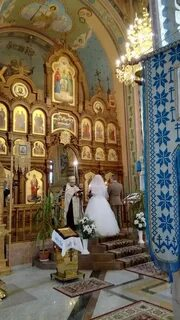

In [ ]:
get_image(data.sample(1)['image'].tolist()[0])

В данных есть выбросы — записи, не относящихся к туристическим или историческим объектам. Я использую TF-IDF: создаем корпус текстов из описаний, применяем TF-IDF, извлекаем наиболее редко или часто встречающиеся слова. Они могут указывать на мусорные данные, такие как мемы, баннеры или личные фото людей. После выделения подозрительных паттернов, можно провести ручную проверку и фильтрацию данных.

чистые сэмплы одного и того же места выдадут примерно одинаковое описание. Есть несколько стратегий, как повысить разнообразие ответов:

- выбор одного самого лучшего:
  - самое длинное описание
  - смое подходящие по мнению LLM
- конкатенация описаний (но важно не сконкатенировать слишком много)

Изображения можно отдать в мета-данные.

In [ ]:
# Сначала посмотрю на распределение длины описаний и частые слова — так проще заметить мусорные записи.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def clean_tourism_data(df: pd.DataFrame) -> pd.DataFrame:
    """Базовая очистка и удаление явных дублей/пустых описаний."""
    result = df.copy()
    text_col = "description" if "description" in result.columns else None
    if text_col is None:
        raise ValueError("В таблице не найдена колонка description")

    result[text_col] = result[text_col].fillna("").astype(str).str.strip()
    result = result[result[text_col].str.len() >= 25].copy()

    # Оставляю только строки с названием и городом: они нужны для поиска.
    for col in ("Name", "City"):
        if col in result.columns:
            result = result[result[col].notna() & result[col].astype(str).str.strip().ne("")]

    # Убираю точные повторы, но не схлопываю разные фотографии одного объекта.
    subset = [c for c in ["WikiData", "Name", "City", text_col] if c in result.columns]
    result = result.drop_duplicates(subset=subset).reset_index(drop=True)

    # TF-IDF нужен здесь скорее как диагностика: очень короткие/нетипичные тексты
    # проверяю по длине, а не удаляю автоматически по одному редкому слову.
    vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=2)
    try:
        matrix = vectorizer.fit_transform(result[text_col])
        result["tfidf_norm"] = np.asarray(matrix.power(2).sum(axis=1)).ravel() ** 0.5
    except ValueError:
        result["tfidf_norm"] = 0.0
    return result

clean_data = clean_tourism_data(data)
print(f"Исходных строк: {len(data):,}; после очистки: {len(clean_data):,}")
display(clean_data[["Name", "City", "description"]].head())


Исходных строк: 14,634; после очистки: 215


,Name,City,description
0,Динамо,Екатеринбург,спорткомплекс в Екатеринбурге
1,№28 Здание городской электростанции «Луч»,Екатеринбург,здание и достопримечательность в Екатеринбурге
2,Дом-музей Бажова,Екатеринбург,Мемориальный дом-музей П. П. Бажова
3,Театр кукол,Екатеринбург,кинотеатр в Екатеринбурге
4,Храм в честь Вознесения Господня,Екатеринбург,Храм Вознесения Господня (Екатеринбург)


 Можно воспользоваться материалами по этой ссылке: [data_connection/vectorstores](https://python.langchain.com/v0.1/docs/modules/data_connection/vectorstores/).



In [ ]:
# Для поиска использую мультиязычную модель: в запросах и описаниях русский язык.
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_core.documents import Document as LangchainDocument

EMBEDDING_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embeddings = HuggingFaceEmbeddings(
    model_name=EMBEDDING_MODEL,
    model_kwargs={"device": "cuda" if torch.cuda.is_available() else "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)

def row_to_text(row):
    parts = [
        f"Достопримечательность: {row.get('Name', '')}",
        f"Город: {row.get('City', '')}",
        f"Описание: {row.get('description', '')}",
    ]
    # Координаты помогают отвечать на вопросы о расположении.
    if pd.notna(row.get("Lat")) and pd.notna(row.get("Lon")):
        parts.append(f"Координаты: широта {row['Lat']}, долгота {row['Lon']}")
    return ". ".join(str(x) for x in parts if str(x).strip() and str(x) != "nan")

docs = []
for _, row in clean_data.iterrows():
    text = row_to_text(row)
    metadata = {
        "name": str(row.get("Name", "")),
        "city": str(row.get("City", "")),
        "wikidata": str(row.get("WikiData", "")),
    }
    docs.append(LangchainDocument(page_content=text, metadata=metadata))

# Разбиваю длинные описания на небольшие перекрывающиеся фрагменты.
splitter = RecursiveCharacterTextSplitter(chunk_size=700, chunk_overlap=100)
chunks = splitter.split_documents(docs)
print(f"Документов: {len(docs):,}; чанков: {len(chunks):,}")

vectorstore = FAISS.from_documents(chunks, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 8})

# ColBERT используется как второй этап ранжирования. Индекс строится по тем же чанкам.
# При отсутствии доступа к модели ниже в RAG останется обычный FAISS-поиск.
try:
    from ragatouille import RAGPretrainedModel
    reranker = RAGPretrainedModel.from_pretrained("colbert-ir/colbertv2.0")
    reranker.index(
        collection=[d.page_content for d in chunks],
        index_name="tourism_rag_index",
        max_document_length=256,
        split_documents=False,
    )
    print("ColBERT reranker загружен.")
except Exception as e:
    reranker = None
    print("ColBERT недоступен, использую FAISS без второго этапа:", repr(e))

def retrieve_context(question: str, k: int = 5) -> List[LangchainDocument]:
    candidates = retriever.invoke(question)
    if reranker is None or not candidates:
        return candidates[:k]
    try:
        ranked = reranker.search(query=question, k=min(k, len(candidates)))
        # Сопоставляю тексты из выдачи ColBERT с исходными LangChain-документами.
        by_text = {d.page_content: d for d in candidates}
        result = []
        for item in ranked:
            content = item.get("content", "")
            if content in by_text:
                result.append(by_text[content])
        return result if result else candidates[:k]
    except Exception as e:
        print("Не получилось выполнить reranking:", repr(e))
        return candidates[:k]

print("Векторная база готова.")


/tmp/ipykernel_400/51414829.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
/tmp/ipykernel_400/51414829.py:8: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Документов: 215; чанков: 215
ColBERT недоступен, использую FAISS без второго этапа: ModuleNotFoundError("No module named 'langchain.retrievers'")
Векторная база готова.


/tmp/ipykernel_400/51414829.py:46: UserWarning: 
********************************************************************************
RAGatouille WARNING: Future Release Notice
--------------------------------------------
RAGatouille version 0.0.10 will be migrating to a PyLate backend 
instead of the current Stanford ColBERT backend.
PyLate is a fully mature, feature-equivalent backend, that greatly facilitates compatibility.
However, please pin version <0.0.10 if you require the Stanford ColBERT backend.
********************************************************************************
  from ragatouille import RAGPretrainedModel


Выполните визуализацию эмбеддингов при помощи метода главных компонент (PCA) и Uniform Manifold Approximation and Projection (UMAP). Пожалуйста, выполните PCA независимо от pacmap.

In [ ]:
# PCA и UMAP строю на одной и той же выборке эмбеддингов для сравнения проекций.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import umap

sample_size = min(1500, len(chunks))
sample_docs = chunks[:sample_size]
texts_for_viz = [d.page_content for d in sample_docs]
vectors = embeddings.embed_documents(texts_for_viz)
X = np.asarray(vectors)

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X)
pca_df = pd.DataFrame({
    "x": pca_coords[:, 0], "y": pca_coords[:, 1],
    "city": [d.metadata.get("city", "неизвестно") for d in sample_docs]
})
fig = px.scatter(pca_df, x="x", y="y", color="city",
                 title="PCA: проекция эмбеддингов описаний")
fig.show()
print("Доля объяснённой дисперсии PCA:", pca.explained_variance_ratio_.sum().round(3))

# UMAP сохраняет локальную структуру лучше, чем линейная проекция PCA.
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                    metric="cosine", random_state=42)
umap_coords = reducer.fit_transform(X)
umap_df = pd.DataFrame({
    "x": umap_coords[:, 0], "y": umap_coords[:, 1],
    "city": [d.metadata.get("city", "неизвестно") for d in sample_docs]
})
px.scatter(umap_df, x="x", y="y", color="city",
           title="UMAP: проекция эмбеддингов описаний").show()


Доля объяснённой дисперсии PCA: 0.403


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



# RAGAS (3 балла)

RAGAS - это система, созданная для автоматической оценки эффективности модели RAG. Она представляет собой комплексный инструмент, способный оценить как качество извлечения информации, так и качество созданного текста. Это достигается благодаря использованию различных метрик, которые анализируют разные аспекты ответов, сгенерированных языковой моделью.



## Метрики оценки в RAGAS

### Faithfulness
Оценивает, насколько ответы языковой модели верно передают информацию, содержащуюся в источниках данных. Это критически важно, чтобы гарантировать, что модель не искажает или не меняет информацию при её интерпретации.

---

$
Faithfulness = \frac{\text{|Number of claims that can be inferred from given context|}}{\text{|Total number of claims in the generated answer|}}
$

### Answer Relevancy
Демонстрирует, насколько ответы соответствуют заданным вопросам. Это важный аспект, так как даже правильный ответ с технической точки зрения может быть ненужным, если он не отвечает на конкретный вопрос пользователя.

---

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} cos(E_{g_i}, E_o)$

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} \frac{E_{g_i} \cdot E_o}{\|E_{g_i}\|\|E_o\|}$

Где:

* $E_{g_i}$ - это эмбеддинг сгенерированного ответа $i$

* $E_o$ - это эмбеддинг исходного вопроса.

* $N$ - это количество сгенерированных вопросов, которое по умолчанию равно 3.

### Context Recall и Context Precision
Эти метрики измеряют эффективность модели в учете контекста вопроса для формирования ответа. "Context Recall" оценивает количество использованной информации из контекста в ответе, в то время как "Context Precision" оценивает точность и релевантность использования контекстной информации.

---

* $ \text{context recall} = \frac{\text{|GT sentences that can be attributed to context|}}{\text{|Number of sentences in GT|}} $
* $Context Precision@k = \frac{\sum \text{precision@k}}{\text{total number of relevant items in the top K results}}$
  * $Precision@k = \frac{\text {true positives@k}}{\text{(true positives@k + false positives@k)}}$

### Answer Semantic Similarity
Оценивает степень семантической близости между ответом модели и эталонным ответом. Это позволяет определить, насколько естественно и точно модель способна воссоздавать человеческий язык.

### Answer Correctness
Оценка корректности ответа. Это последний шаг в проверке, чтобы убедиться, предоставляет ли модель точную и достоверную информацию в своем ответе.

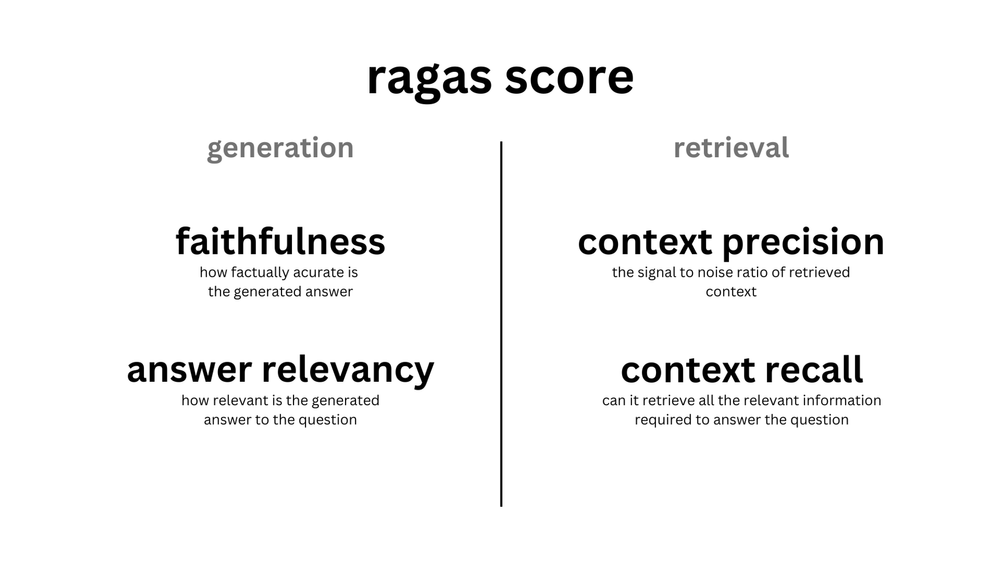

В этом задании вам нужно реализовать метрику answer_relevancy в коде. Опционально за допбаллы можно реализовать другие метрики.

Для этого датасет нужно привести к виду, в котором будут следующие поля:

### 1. question
- Смысл: Эта колонка содержит вопросы, на которые нужно найти ответы. В контексте задач QA, это основная информация, которую модель должна обработать для генерации ответа.
- Пример: "Каковы преимущества RAG?"

### 2. ground_truths
- Смысл: В этой колонке находятся правильные ответы на соответствующие вопросы. Это может использоваться для оценки производительности модели, так как позволяет сравнить сгенерированные ответы с эталонными.
- Пример: "RAG улучшает качество генерации, используя внешние источники информации."

### 3. answer
- Смысл: Эта колонка содержит ответы, которые генерирует модель на основе заданных вопросов. Это может быть результат работы модели, которую вы тестируете или обучаете.
- Пример: "RAG позволяет моделям извлекать информацию из внешних источников, что улучшает их способность отвечать на сложные вопросы."

### 4. contexts
- Смысл: Эта колонка предоставляет контекст или дополнительную информацию, которая может быть полезна для понимания вопроса или для формирования ответа. Это может быть текст, из которого был извлечен ответ, или другие релевантные документы.
- Пример: "RAG (Retrieval-Augmented Generation) — это метод, который использует внешние базы данных для получения информации при генерации текста."

HINT: Поле question можно тоже сгенерировать. Например, можно попросить модель задать вопрос по описанию изображения.

HINT: Для answer_relevancy нужны не все поля

HINT: Инференс такого эксперимента может быть долгим. План минимум: возьмите 100 случайных сэмплов.

In [ ]:
def data_preprocess(df: pd.DataFrame, sample_size: int = 100, random_state: int = 42) -> pd.DataFrame:
    """
    Готовит данные для оценки answer_relevancy.
    Возвращает question, ground_truths, answer, contexts.
    Вопрос формирую из названия и города, чтобы не требовать отдельной LLM-генерации.
    """
    required = {"Name", "City", "description"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Не хватает колонок: {missing}")

    work = df.dropna(subset=["Name", "City", "description"]).copy()
    work["description"] = work["description"].astype(str).str.strip()
    work = work[work["description"].str.len() > 30]
    if len(work) > sample_size:
        work = work.drop_duplicates(subset=["WikiData"] if "WikiData" in work else ["Name", "City"])
        work = work.sample(n=min(sample_size, len(work)), random_state=random_state)

    rows = []
    for _, row in work.iterrows():
        name, city, description = str(row["Name"]), str(row["City"]), str(row["description"])
        question = f"Что представляет собой {name} и чем он примечателен в городе {city}?"
        rows.append({
            "question": question,
            "ground_truths": description,
            "answer": "",  # Заполняется ответом RAG в следующей части.
            "contexts": [description],
        })
    return pd.DataFrame(rows).reset_index(drop=True)


In [ ]:
!pip install -q sentence-transformers transformers torch numpy

In [ ]:
from typing import Optional
import numpy as np
import torch
from sentence_transformers import SentenceTransformer
from transformers import pipeline

In [ ]:
def answer_relevancy(
    question: str,
    answer: str,
    model: Optional[SentenceTransformer] = None,
    n_questions: int = 3,
    generator=None,
) -> float:
    """
    Упрощённая реализация Answer Relevancy из RAGAS.
    Генерирую несколько вопросов, на которые данный ответ мог бы отвечать,
    и усредняю cosine similarity их эмбеддингов с эмбеддингом исходного вопроса.
    """
    if not answer or not answer.strip():
        return 0.0

    if model is None:
        model = SentenceTransformer(EMBEDDING_MODEL)

    if generator is None:
        generator = pipeline(
            "text-generation",
            model="Qwen/Qwen2.5-1.5B-Instruct",
            device=0 if torch.cuda.is_available() else -1,
        )

    messages = [
        {
            "role": "system",
            "content": "Составь один краткий вопрос на русском языке, ответом на который является приведённый текст. Выведи только сам вопрос без лишних слов."
        },
        {
            "role": "user",
            "content": answer[:1200]
        }
    ]

    generated = generator(
        [messages] * n_questions,
        max_new_tokens=64,
        do_sample=True,
        temperature=0.7,
    )

    # При передаче батча сообщений pipeline возвращает список списков: [[{'generated_text': [...]}], ...]
    generated_questions = [
        item[0]["generated_text"][-1]["content"].strip()
        for item in generated
    ]
    generated_questions = [q for q in generated_questions if q]

    if not generated_questions:
        return 0.0

    vectors = model.encode(
        [question] + generated_questions,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    similarities = vectors[1:] @ vectors[0]
    return float(np.mean(similarities))


# Протестируйте ваш RAG (3 балла)

In [ ]:
import torch
from transformers import pipeline

# Загружаем лёгкую русскоязычную chat-модель
qa_generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    device=0 if torch.cuda.is_available() else -1,
)

def rag_answer(question: str, k: int = 5) -> Tuple[str, List[str]]:
    found_docs = retrieve_context(question, k=k)
    context = "\n\n".join(d.page_content for d in found_docs)

    messages = [
        {
            "role": "system",
            "content": "Ответь на вопрос строго по контексту. Не добавляй факты, которых нет в контексте. Если информации недостаточно, так и скажи."
        },
        {
            "role": "user",
            "content": f"Контекст:\n{context[:3500]}\n\nВопрос: {question}"
        }
    ]

    output = qa_generator(messages, max_new_tokens=180, do_sample=False)
    # Извлекаем только текст ответа ассистента
    answer = output[0]["generated_text"][-1]["content"].strip()
    return answer, [d.page_content for d in found_docs]


test_questions = [
    "Что интересного можно посмотреть в Екатеринбурге?",
    "Что представляет собой Динамо в Екатеринбурге?",
    "Какие сведения есть об исторических зданиях в Москве?",
]
test_results = []
for question in test_questions:
    answer, contexts = rag_answer(question)
    test_results.append({"question": question, "answer": answer, "contexts": contexts})
    print("\nВопрос:", question, "\nОтвет:", answer, "\nНайдено фрагментов:", len(contexts))

display(pd.DataFrame(test_results)[["question", "answer"]])


# Считаю answer_relevancy на 100 примерах, как рекомендовано в задании.
eval_data = data_preprocess(clean_data, sample_size=100)
eval_rows = []
relevancy_model = SentenceTransformer(EMBEDDING_MODEL)
for _, row in tqdm(eval_data.iterrows(), total=len(eval_data)):
    answer, contexts = rag_answer(row["question"])
    score = answer_relevancy(
        row["question"], answer,
        model=relevancy_model,
        n_questions=3,
        generator=qa_generator,
    )
    eval_rows.append({
        "question": row["question"],
        "ground_truths": row["ground_truths"],
        "answer": answer,
        "contexts": contexts,
        "answer_relevancy": score,
    })

ragas_like_results = pd.DataFrame(eval_rows)
print("Средняя Answer Relevancy:", ragas_like_results["answer_relevancy"].mean().round(3))
display(ragas_like_results[["question", "answer", "answer_relevancy"]].head())


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

... (6 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Средняя Answer Relevancy: 0.826


,question,answer,answer_relevancy
0,Что представляет собой Горьковчане фронту и че...,Горьковчане фронту - это название улицы в Нижн...,0.760798
1,Что представляет собой Церковь Рождества Иоана...,Церковь Рождества Иоана Предтечи является одно...,0.805386
2,Что представляет собой Дом Степанова и чем он ...,Дом Степанова - это историческое здание в Екат...,0.763588
3,Что представляет собой Собор Александра Невско...,Собор Александра Невского является одним из са...,0.852474
4,Что представляет собой Музей зарубежного искус...,Музей зарубежного искусства расположен в город...,0.835486


# Дополнительная часть (+3 балла)

Реализуйте одну из метрик retrieval-части на выбор.

Для того, чтобы понять model as a judge подход из RAGAS, советуем посетить [этот кукбук](https://huggingface.co/learn/cookbook/en/rag_evaluation)

In [ ]:
# В качестве retrieval-метрики реализую Context Precision@k.
# Релевантность  размечается простым совпадением ключевых слов из эталонного текста.
import re
def context_precision_at_k(
    retrieved_contexts: List[str],
    ground_truth: str,
    k: int = 5,
    overlap_threshold: float = 0.25, # минимум 25% ключевых слов должны совпасть
) -> float:
    if isinstance(ground_truth, list):
        ground_truth = " ".join(ground_truth)
    if not retrieved_contexts or not ground_truth:
        return 0.0

    stop_words = {
        "это", "как", "что", "для", "при", "или", "его", "ее", "они", "также",
        "был", "была", "были", "есть", "этот", "эта", "эти", "the", "and", "with",
        "году", "года", "очень", "можно", "который", "которая", "которые"
    }
    terms = {
        w.lower() for w in re.findall(r"[A-Za-zА-Яа-яЁё]{4,}", ground_truth)
        if w.lower() not in stop_words
    }
    if not terms:
        return 0.0

    hits = []
    for context in retrieved_contexts[:k]:
        words = set(w.lower() for w in re.findall(r"[A-Za-zА-Яа-яЁё]{4,}", context))
        # Считаем долю совпавших ключевых слов из ground_truth
        overlap = len(terms & words) / len(terms)
        hits.append(overlap >= overlap_threshold)

    relevant_total = sum(hits)
    if relevant_total == 0:
        return 0.0

    precisions = [sum(hits[:i + 1]) / (i + 1) for i, hit in enumerate(hits) if hit]
    return float(sum(precisions) / relevant_total)


In [ ]:

precision_scores = []
for item in test_results:
    matching = next(
        (d["description"] for _, d in clean_data.iterrows()
         if str(d.get("Name", "")) in item["question"]),
        item["answer"]
    )
    precision_scores.append(context_precision_at_k(item["contexts"], matching, k=5))

print("Средний Context Precision@5:", np.mean(precision_scores).round(3))


if "ragas_like_results" in globals() and len(ragas_like_results):
    cp_scores = [
        context_precision_at_k(row["contexts"], row["ground_truths"], k=5)
        for _, row in ragas_like_results.iterrows()
    ]
    ragas_like_results["context_precision_at_5"] = cp_scores
    print("Средний Context Precision@5:", np.mean(cp_scores).round(3))


Средний Context Precision@5: 0.333
Средний Context Precision@5: 0.813
